# PC02 — Phân tích đặc trưng RFM và thiết kế cách biểu diễn khách hàng

## Mục tiêu nghiệp vụ
Hai khách có thể giống nhau về tổng tiền nhưng khác nhau về số lần mua hoặc thời điểm lần mua cuối. Đồng thời, Monetary có thể lớn hàng trăm nghìn trong khi Frequency chỉ vài đơn. Nếu dùng khoảng cách trực tiếp, mô hình có thể phản ánh thang số nhiều hơn hành vi.

PC02 nghiên cứu **dữ liệu đang phân bố ra sao và nên biểu diễn khách thế nào** trước khi thử mô hình. Việc biến đổi phải có lý do, không chọn chỉ vì biểu đồ trông đẹp hoặc mong muốn đủ một số nhóm định trước.

## Các câu hỏi trọng tâm
- Khách một đơn chiếm bao nhiêu và đóng góp giá trị thế nào?
- Đuôi F/M có phải lỗi, hay là những khách đáng nghiên cứu?
- F, M và khoảng lịch sử quan sát liên hệ ra sao?
- StandardScaler và log làm thay đổi khoảng cách giữa khách như thế nào?
- Biến hành vi nào cung cấp góc nhìn mới, biến nào trùng thông tin RFM?

Kết quả là cơ sở cho hai thí nghiệm TN1/TN2 trên cùng tập khách. **Chưa chấm điểm RFM 1–5, chưa đặt tên cụm và chưa suy nguyên nhân kinh doanh.**


## Bản đồ ký hiệu và nguyên tắc đọc công thức

| Ký hiệu | Ý nghĩa trong notebook |
|---|---|
| c / i | Khách / chỉ số điểm dữ liệu; đọc định nghĩa tại từng công thức |
| o | Một order_id; không phải một dòng sản phẩm |
| E | Tập khách đủ điều kiện RFM delivered |
| T | Mốc31/12/2022 |
| n | Số khách của tập đang phân tích |
| k, Cj | Số cụm và tập khách của cụm j |
| R/F/M | Giá trị thô trên cùng tập đơn đủ điều kiện |
| x, z | Giá trị trước/sau biến đổi theo ngữ cảnh |
| μ, σ | Trung bình/tâm và độ lệch chuẩn, định nghĩa cụ thể cạnh công thức |

Một ký hiệu có thể dùng ở cấp khác trong một công thức khác; mỗi mục đều giải thích phạm vi và mẫu số. Đọc đơn vị, thời gian và trạng thái trước khi so số. Công thức minh họa và kết quả dự án được tách rõ. Các hàm Python giữ tên tiếng Anh để tái sử dụng; nội dung trình bày bằng tiếng Việt.


## Chuẩn bị môi trường và nguồn dữ liệu

Chạy với dữ liệu mô hình đã lưu trong data/model/phan_khuc/v1. Để huấn luyện lại từ PC03, đặt biến môi trường DATATHON_MODEL_RUN thành một tên lượt mới.

In [1]:
from pathlib import Path
import sys
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

from ham_dung_chung import segmentation_study
Study = segmentation_study().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "v1")
study = Study(ROOT, "PC02")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC02 | Thư mục kết quả: /workspace/scratch/1f9612b45e80/professional/DA_PC/reports/segmentation/professional_v1/PC02


## PC02.1 — Đọc phân bố, phân vị và độ lệch của RFM

**Câu hỏi:** khách điển hình và khách ở đuôi phân bố khác nhau thế nào?

Trung bình có thể bị kéo lên bởi một số giá trị lớn. Trung vị là phân vị 50%, hữu ích khi F/M lệch phải. Bảng dùng thêm P10/P90/P99 để đọc độ phân tán, không lấy max đại diện phần lớn khách.

Với dãy tăng dần $x_0,\ldots,x_{n-1}$ và xác suất $p$, phân vị tuyến tính dùng:

$$h=(n-1)p,\quad j=\lfloor h\rfloor,\quad w=h-j,$$

$$Q_p=(1-w)x_j+w x_{j+1}.$$

Khi $p=1$, lấy giá trị cuối dãy; không truy phần tử ngoài dãy. Ví dụ dãy 1,2,4,9 có median=3 do nội suy giữa 2 và 4; phân vị có thể không trùng giá trị quan sát.

Độ lệch chuẩn trong bảng thống kê dùng quy ước mẫu:

$$s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}.$$

Trong khi StandardScaler ở mục sau dùng mẫu số $n$. Hai quy ước phục vụ mục đích khác nhau, không coi chênh lệch là lỗi.

**Cách đọc hình:** histogram gốc cho thấy độ lớn thực; hình log chỉ đổi cách hiển thị để nhìn đuôi. Một hình trông cân đối hơn sau log chưa chứng minh mô hình tốt hơn. Độ lệch mẫu là thống kê mô tả, không phải phép kiểm định dữ liệu phải có phân phối chuẩn.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [2]:
# VÍ DỤ GIẢ LẬP: phân vị nội suy, khác số quan sát thực.
toy_values=np.array([1.,2.,4.,9.]);toy_rows=[]
for toy_p in [.25,.5,.75]:
 toy_h=(len(toy_values)-1)*toy_p;toy_j=int(np.floor(toy_h));toy_w=toy_h-toy_j;toy_q=(1-toy_w)*toy_values[toy_j]+toy_w*toy_values[toy_j+1]
 assert np.isclose(toy_q,np.quantile(toy_values,toy_p))
 toy_rows.append({'p':toy_p,'h=(n−1)p':toy_h,'j':toy_j,'w':toy_w,'Q tính tay':toy_q})
study.table('VD02_phan_vi','Ví dụ giả lập — phân vị dãy1,2,4,9',pd.DataFrame(toy_rows))

Out[2]: 
      p  h=(n−1)p  j     w  Q tính tay
0  0.25      0.75  0  0.75        1.75
1  0.50      1.50  1  0.50        3.00
2  0.75      2.25  2  0.25        5.25


,p,h=(n−1)p,j,w,Q tính tay
0,0.25,0.75,0,0.75,1.75
1,0.50,1.50,1,0.50,3.00
2,0.75,2.25,2,0.25,5.25


,feature,count,mean,std,min,1%,10%,25%,50%,75%,90%,95%,99%,max,skew,zero_count
0,Recency,85115.0,1327.202573,1029.358243,0.00,11.0000,157.000,395.00,1142.00,2046.000,2868.000,3289.000,3702.000,3832.00,0.578526,67
1,Frequency,85115.0,6.070798,7.040892,1.00,1.0000,1.000,1.00,3.00,8.000,15.000,20.000,34.000,93.00,2.592908,0
2,Monetary,85115.0,147073.676287,179937.427009,445.65,1988.7224,10018.326,28544.99,79730.85,198288.885,376092.328,513558.654,829222.161,2883271.24,2.521905,0


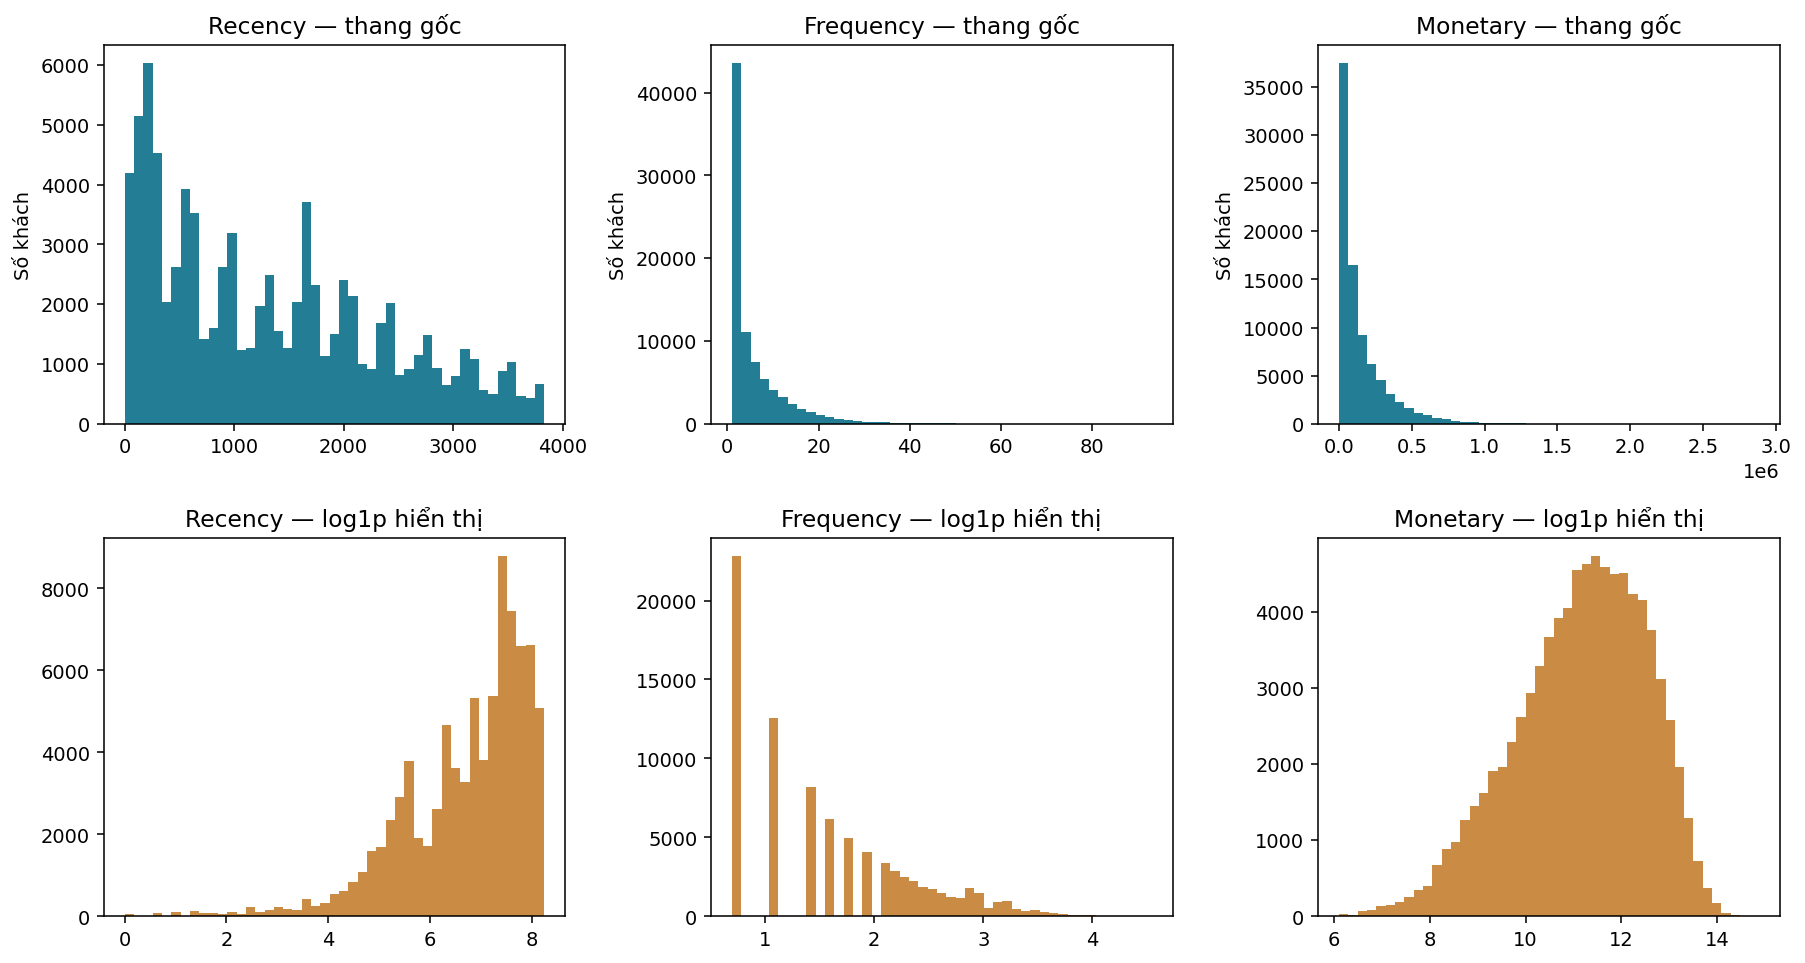

Độ lệch F/M cần đọc cùng P99/max; log nén đuôi, không sửa lỗi nguồn và không bảo đảm tạo cụm tốt hơn.

In [3]:
f=study.f.copy();summary=study.table('rfm_distribution','Thống kê RFM',distribution(f))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for j,col in enumerate(FEATURES):
 values=f[col].astype(float);axes[0,j].hist(values,bins=45,color='#237d95');axes[0,j].set(title=col+' — thang gốc',ylabel='Số khách');axes[1,j].hist(np.log1p(values),bins=45,color='#ca8b45');axes[1,j].set(title=col+' — log1p hiển thị')
study.fig('rfm_histograms','Phân bố gốc và log hiển thị',fig)
study.note('Độ lệch F/M cần đọc cùng P99/max; log nén đuôi, không sửa lỗi nguồn và không bảo đảm tạo cụm tốt hơn.')

## PC02.2 — Khách một đơn: quy mô và đóng góp

**Câu hỏi:** nhiều khách ít mua có đồng nghĩa phần lớn giá trị đến từ họ không?

Với nhóm tần suất $B$, cần hai mẫu số:

$$p_B=\frac{\#\{c:F_c\in B\}}{|E|},$$

$$m_B=\frac{\sum_{c:F_c\in B}M_c}{\sum_{c\in E}M_c}.$$

$p_B$ là tỷ trọng khách, $m_B$ là tỷ trọng Net. Các nhóm 1;2–3;4–7;8–15;16+ đơn rời nhau và phủ tập có F≥1, nên từng cột tỷ trọng cộng thành 100% trong sai số hiển thị.

Khách có một đơn chưa có khoảng cách giữa hai lần mua để đo. Với F≥2, trung bình khoảng cách giữa các đơn sắp theo ngày có thể tính bằng:

$$Gap_c=\frac{t_{last,c}-t_{first,c}}{F_c-1}.$$

Hai đơn cùng ngày tạo khoảng cách 0 là hợp lệ; một đơn thì mẫu số 0 và chỉ tiêu để thiếu có chủ đích. Không điền 0 cho khách một đơn vì sẽ làm họ giống khách mua liên tiếp trong cùng ngày.

**Ý nghĩa:** một nhóm đông khách nhưng tỷ trọng Net nhỏ gợi ý câu hỏi về mức đóng góp, chưa chứng minh tiềm năng hoặc chi phí chăm sóc. Các ngưỡng nhóm Frequency chỉ giúp đọc dữ liệu, không phải nhãn phân khúc do mô hình học được.


,frequency_band,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,1 đơn,22843,5.480755e+08,2342.0,1.0,16636.000,0.268378,0.043782
1,2–3 đơn,20746,1.174401e+09,1621.0,2.0,48922.155,0.243741,0.093816
2,4–7 đơn,18629,2.364555e+09,888.0,5.0,118657.080,0.218869,0.188890
3,8–15 đơn,15062,3.991445e+09,474.5,10.0,254429.310,0.176961,0.318852
4,16+ đơn,7835,4.439699e+09,230.0,21.0,522832.940,0.092052,0.354660


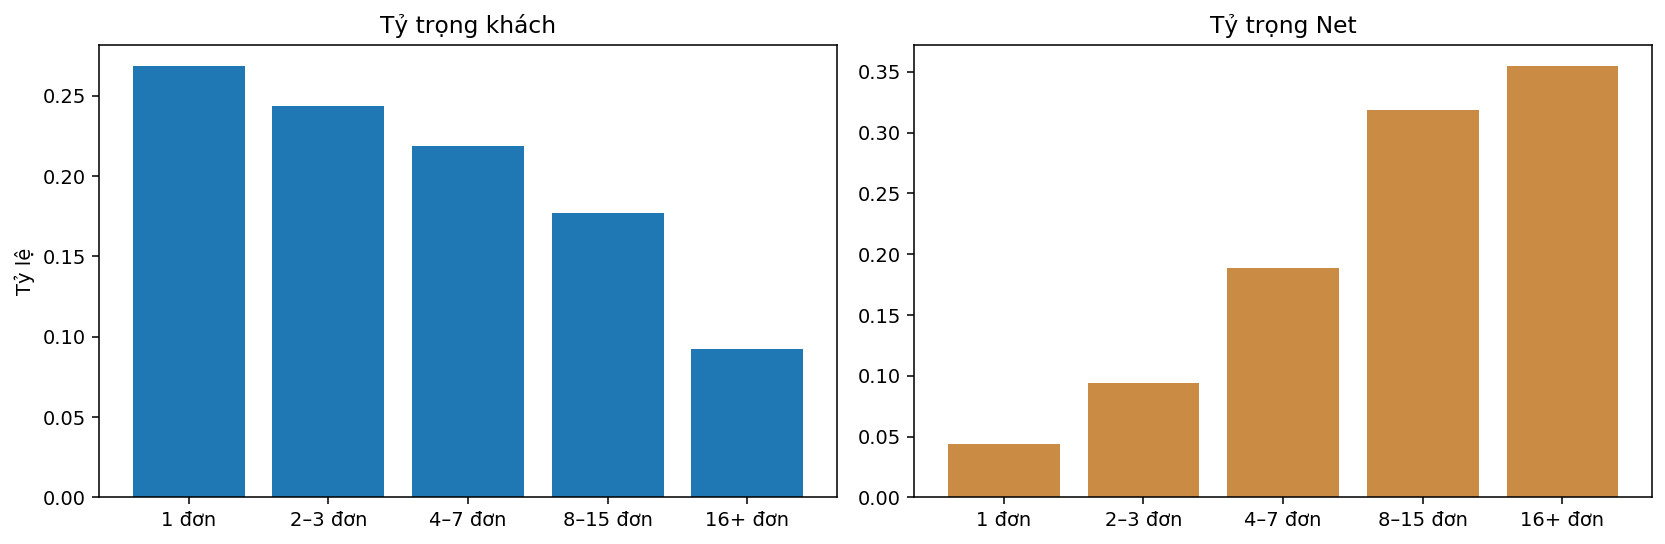

Có 22,843 khách một đơn (26.84%), đóng góp 4.38% Net. Không tính mean_gap=0 cho nhóm này; chưa quan sát lần mua thứ hai.

In [4]:
f['frequency_band']=pd.cut(f.Frequency,[0,1,3,7,15,np.inf],labels=['1 đơn','2–3 đơn','4–7 đơn','8–15 đơn','16+ đơn'])
t=study.table('frequency_bands','Quy mô và đóng góp theo Frequency',share_table(f,'frequency_band'))
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].bar(t.frequency_band.astype(str),t.customer_share);axes[0].set(title='Tỷ trọng khách',ylabel='Tỷ lệ');axes[1].bar(t.frequency_band.astype(str),t.Monetary_share,color='#ca8b45');axes[1].set(title='Tỷ trọng Net');study.fig('frequency_contribution','Khách và Net theo số đơn',fig)
one=f.Frequency.eq(1);study.note(f'Có {one.sum():,} khách một đơn ({one.mean():.2%}), đóng góp {float(sum(f.loc[one,"Monetary"],Decimal(0))/sum(f.Monetary,Decimal(0))):.2%} Net. Không tính mean_gap=0 cho nhóm này; chưa quan sát lần mua thứ hai.')

## PC02.3 — Recency và hoạt động gần cuối kỳ

**Câu hỏi:** khách còn có đơn delivered gần mốc chốt hay chỉ có đóng góp quá khứ?

Chia R thành các khoảng mô tả 0–30;31–90;91–180;181–365;366–730;731+ ngày. Đây là nhóm theo số ngày chênh lệch, không mô hình churn và không chứng minh một chu kỳ mua bình thường của ngành.

Với ngưỡng $L$, tập gần đây là:

$$A_L=\{c\in E:R_c\leq L\}.$$

Tỷ trọng khách gần đây là $|A_L|/|E|$. Nhưng R=0 đến R=30 bao gồm 31 giá trị ngày lịch. Nếu câu hỏi là “đúng 30 ngày cuối”, phải xác định khoảng ngày bao gồm hai đầu, không dùng hai cách gọi thay thế nhau.

**Ví dụ:** một khách từng mua nhiều trong năm 2015 nhưng không mua về cuối kỳ có thể M tích lũy cao và R lớn. Vì vậy, đọc M đơn độc dễ nhầm đóng góp quá khứ với hoạt động hiện tại. Trong nghiên cứu này “hiện tại” luôn là tương đối với mốc cuối năm 2022, không phải năm thực hiện đồ án.

**Quyết định:** giữ cả R/F/M để phân biệt những tình huống đó. Trước khi gọi nhóm lâu chưa mua là rời bỏ, cần chu kỳ mua, dữ liệu sự kiện và một định nghĩa churn hợp lệ mà bộ nguồn chưa cung cấp.


,recency_band,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0–30,1769,5.874104e+08,11.0,11.0,260516.650,0.020784,0.046925
1,31–90,2591,8.961750e+08,62.0,11.0,278993.270,0.030441,0.071590
2,91–180,5414,1.636440e+09,132.0,10.0,238267.740,0.063608,0.130725
3,181–365,10658,2.764691e+09,251.0,8.0,202484.695,0.125219,0.220854
4,366–730,12187,2.484984e+09,556.0,7.0,157942.000,0.143183,0.198510
5,731+,52496,4.148475e+09,1804.0,2.0,45971.615,0.616766,0.331396


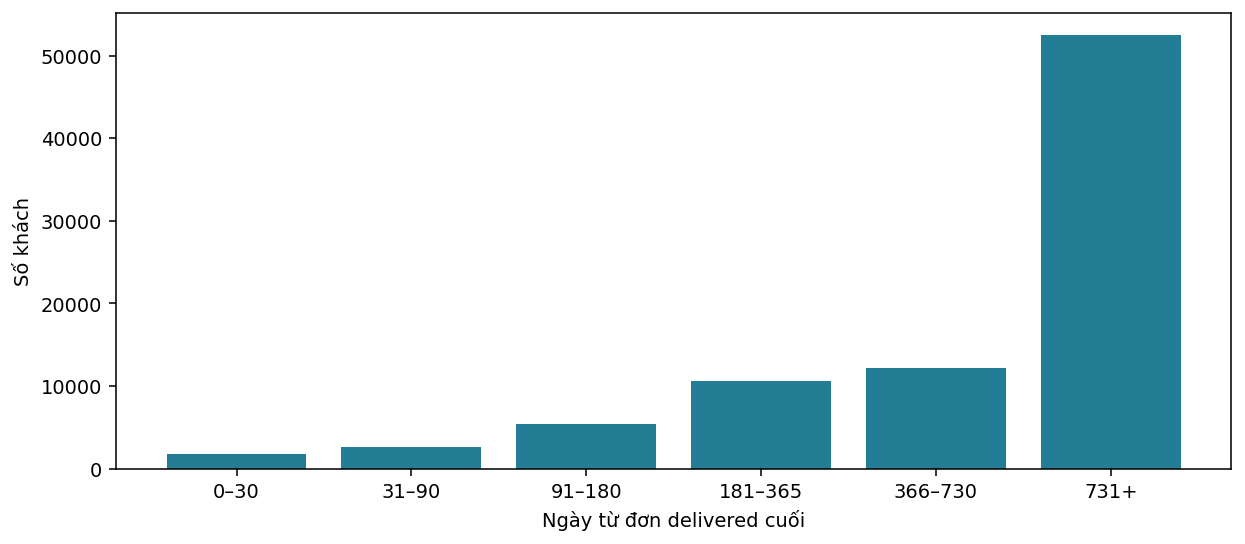

Net là tích lũy toàn lịch sử: khách lâu chưa mua vẫn có thể đóng góp lớn trong quá khứ. Không dùng M tích lũy để chứng minh đang hoạt động tốt.

In [5]:
f['recency_band']=pd.cut(f.Recency,[-1,30,90,180,365,730,np.inf],labels=['0–30','31–90','91–180','181–365','366–730','731+'])
t=study.table('recency_bands','Khách và Net theo Recency',share_table(f,'recency_band'))
fig,ax=plt.subplots(figsize=(9,4));ax.bar(t.recency_band.astype(str),t.customers,color='#237d95');ax.set(xlabel='Ngày từ đơn delivered cuối',ylabel='Số khách');study.fig('recency_bands','Phân bố nhóm Recency',fig)
study.note('Net là tích lũy toàn lịch sử: khách lâu chưa mua vẫn có thể đóng góp lớn trong quá khứ. Không dùng M tích lũy để chứng minh đang hoạt động tốt.')

## PC02.4 — Mức tập trung Monetary và đường tích lũy

**Câu hỏi:** giá trị giao dịch phân bổ rộng hay tập trung vào ít khách?

Sắp M giảm dần. Với tỷ lệ top $p$, chọn $k=\lceil np\rceil$ khách và tính:

$$TopShare(p)=\frac{\sum_{i=1}^{k}M_{(i)}}{\sum_{i=1}^{n}M_{(i)}}.$$

$M_{(i)}$ ở đây được sắp giảm dần. Báo rõ số khách thực chọn vì làm tròn có thể khiến tập top không đúng chính xác p% mã. Khi tiền bằng nhau ở biên, số người được chọn vẫn theo k; báo tỷ trọng tiền, không dùng danh tính cá nhân để diễn giải.

Đường tích lũy trong hình lại sắp M **tăng dần**: trục ngang là tỷ trọng khách từ thấp lên cao, trục dọc là tỷ trọng Net tích lũy. Đường càng nằm dưới đường đều, giá trị càng tập trung. Đây không phải đường dự báo hay đường ROC.

**Ví dụ giả lập:** M của năm khách là 1,1,2,2,14. Top20%=một khách đóng góp 14/20=70%. Con số đó chỉ nói về tập trung tiền, không chứng minh quy tắc 80/20 luôn đúng hoặc khách top sẽ tiếp tục có giá trị cao.

**Liên hệ nghiệp vụ:** kết quả giúp đặt câu hỏi về phụ thuộc vào nhóm giá trị cao và nhu cầu đọc kỹ đuôi. Chưa có COGS/chi phí theo khách đủ điều kiện để chuyển tỷ trọng Net thành tỷ trọng lợi nhuận.


,top_customer_fraction,selected_customers,monetary_share
0,0.01,852,0.070663
1,0.05,4256,0.242350
2,0.10,8512,0.391048
3,0.20,17023,0.595130
4,0.50,42558,0.889816


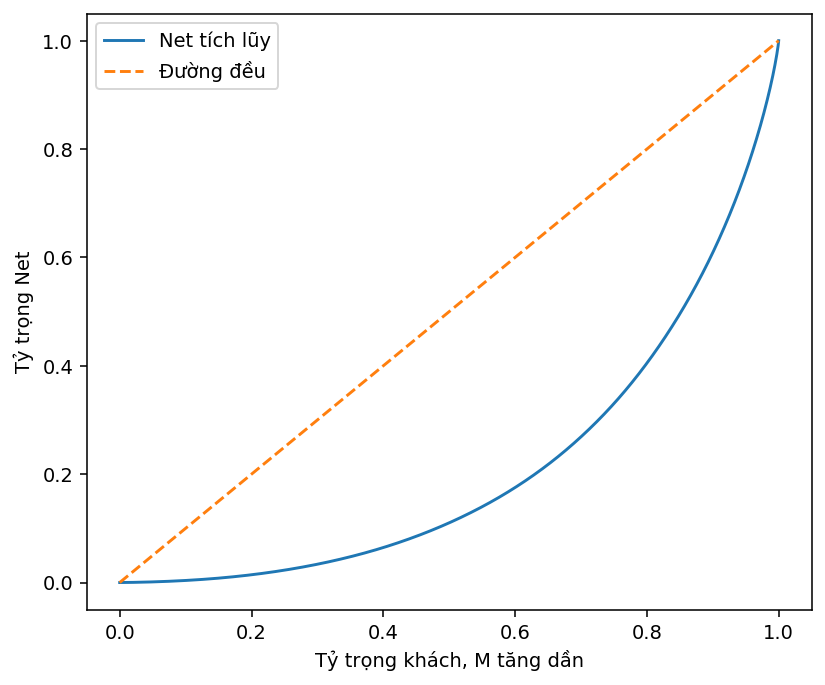

Top10% khách (làm tròn số khách lên) đóng góp 39.10% Net. Đây là tập trung giá trị giao dịch, chưa phải lợi nhuận/CLV.

In [6]:
top=study.table('monetary_concentration','Mức độ tập trung Net',concentration(f))
v=np.sort(f.Monetary.astype(float).to_numpy());cum=np.r_[0,np.cumsum(v)/v.sum()];x=np.linspace(0,1,len(cum))
fig,ax=plt.subplots(figsize=(6,5));ax.plot(x,cum,label='Net tích lũy');ax.plot([0,1],[0,1],'--',label='Đường đều');ax.set(xlabel='Tỷ trọng khách, M tăng dần',ylabel='Tỷ trọng Net');ax.legend();study.fig('lorenz','Đường tập trung Monetary',fig)
study.note(f'Top10% khách (làm tròn số khách lên) đóng góp {top.loc[top.top_customer_fraction.eq(.1),"monetary_share"].iloc[0]:.2%} Net. Đây là tập trung giá trị giao dịch, chưa phải lợi nhuận/CLV.')

## PC02.5 — Quan hệ giữa đặc trưng và cơ hội được quan sát

**Câu hỏi:** đưa nhiều biến vào có làm cùng một thông tin được tính lặp?

M là tổng giá trị đơn nên thường liên hệ F. AOV lại được định nghĩa $AOV_c=M_c/F_c$, vì vậy thêm đồng thời R,F,M,AOV có thể làm yếu tố giá trị/tần suất được nhấn nhiều lần, dù số cột tăng.

Spearman dùng tương quan giữa thứ hạng:

$$\rho_s=Corr(rank(X),rank(Y)).$$

Khi có đồng hạng, dùng thứ hạng trung bình; không áp dụng công thức rút gọn chỉ dành cho dữ liệu không đồng hạng. Hệ số mô tả liên hệ đơn điệu, không đo tác động nhân quả. Tương quan thấp cũng chưa chứng minh hai biến độc lập.

Khoảng lịch sử quan sát:

$$Span_c=t_{last,c}-t_{first,c}.$$

Span lớn có thể đi cùng nhiều đơn, nhưng chính việc có nhiều đơn mới tạo cơ hội xuất hiện khoảng first–last dài. Span không phải tuổi khách và signup_date chưa là thời điểm bắt đầu mua. Do đó không chia F/M cho Span rồi tự gọi là giá trị hằng năm; khách một đơn có Span=0, còn mức tiếp xúc thực tế chưa biết.

**Quyết định:** baseline giữ ba trục RFM. Biến bổ sung được mô tả và thẩm định thông tin mới trước khi tạo thí nghiệm mở rộng, thay vì thêm tất cả vào khoảng cách.


,Đặc trưng,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn),observed_span_days
0,Recency,1.000000,-0.648940,-0.621314,-0.783065
1,Frequency,-0.648940,1.000000,0.899148,0.897844
2,Monetary,-0.621314,0.899148,1.000000,0.808885
3,observed_span_days,-0.783065,0.897844,0.808885,1.000000


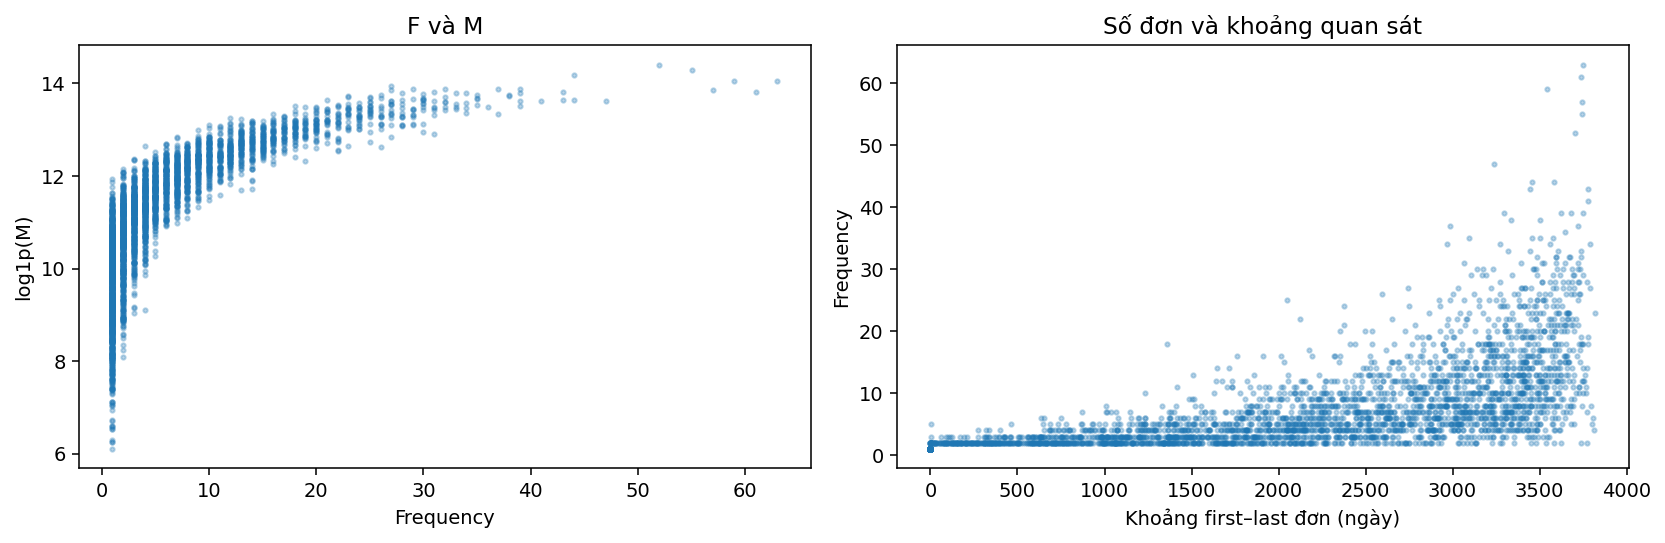

Spearman(F,M)=0.899; Spearman(F,khoảng quan sát)=0.898. Không suy nguyên nhân, không chia F cho khoảng first–last để gọi là tần suất năm khi nhiều khách có span=0.

In [7]:
corr=f[FEATURES+['observed_span_days']].astype(float).corr(method='spearman')
study.table('spearman','Tương quan Spearman',corr.reset_index(names='Đặc trưng'))
rng=np.random.default_rng(42);sample=f.iloc[rng.choice(len(f),min(4000,len(f)),replace=False)]
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].scatter(sample.Frequency,np.log1p(sample.Monetary.astype(float)),s=5,alpha=.3);axes[0].set(xlabel='Frequency',ylabel='log1p(M)',title='F và M');axes[1].scatter(sample.observed_span_days,sample.Frequency,s=5,alpha=.3);axes[1].set(xlabel='Khoảng first–last đơn (ngày)',ylabel='Frequency',title='Số đơn và khoảng quan sát');study.fig('rfm_relationships','Quan hệ giữa các đặc trưng',fig)
study.note(f'Spearman(F,M)={corr.loc["Frequency","Monetary"]:.3f}; Spearman(F,khoảng quan sát)={corr.loc["Frequency","observed_span_days"]:.3f}. Không suy nguyên nhân, không chia F cho khoảng first–last để gọi là tần suất năm khi nhiều khách có span=0.')

## PC02.6 — Ngoại lệ: phát hiện để hiểu, không tự động xóa

**Câu hỏi:** khách ở đuôi là lỗi hay là đối tượng quan trọng của phân khúc?

Khoảng tứ phân vị:

$$IQR=Q_{0.75}-Q_{0.25}.$$

Hàng rào trên thường dùng để rà soát:

$$U=Q_{0.75}+1.5IQR.$$

Giá trị vượt U hoặc P99 là “cực đoan theo quy tắc mô tả”, chưa phải lỗi. Trong phân khúc, các khách nhiều đơn/giá trị cao có thể chính là nhóm cần giữ. Quy tắc IQR cũng có thể gắn cờ rất nhiều khách khi phân bố lệch phải.

**Ví dụ giả lập:** F=1,1,2,2,3,30. Giá trị30 khác phần lớn mẫu nhưng vẫn có thể là khách mua thường xuyên hợp lệ. Xóa nó sẽ làm thay đổi câu hỏi, còn cap30 xuống một ngưỡng sẽ làm giảm khác biệt hành vi.

Bảng dưới báo riêng số vượt từng ngưỡng và các trường hợp giá trị cao. Một khách có thể vượt nhiều ngưỡng, không cộng số đếm thành tổng “khách lỗi”. Rà soát mã/tập đơn/tiền trước khi quyết định sửa; các bản ghi thiếu hoặc không hợp lệ kỹ thuật đã bị cổng dữ liệu chặn.

**Quyết định cho thí nghiệm chính:** không cap/xóa ngoại lệ hợp lệ. So sánh giữ gốc với log(F,M); nếu cần thử cap hoặc RobustScaler phải công bố là phương án độ nhạy riêng.


In [8]:
rows=[]
for col in FEATURES:
 values=f[col].astype(float);q1,q3=values.quantile([.25,.75]);p99=values.quantile(.99);upper=q3+1.5*(q3-q1)
 rows.append({'Đặc trưng':col,'P99':p99,'Vượt P99':int((values>p99).sum()),'Ngưỡng IQR trên':upper,'Vượt IQR trên':int((values>upper).sum()),'Max':values.max()})
study.table('tail_audit','Các ngưỡng mô tả đuôi',pd.DataFrame(rows))
study.table('top_monetary_cases','Khách giá trị cao — mẫu rà soát',f.sort_values('Monetary',ascending=False)[['customer_id','Recency','Frequency','Monetary','observed_span_days']].head(10))
study.note('Một khách có thể vượt nhiều ngưỡng; không cộng các số đếm thành tổng lỗi. Chưa có bằng chứng để cap/xóa. PC03 so log(F,M) với giữ gốc thay vì tự loại khách.')

,Đặc trưng,P99,Vượt P99,Ngưỡng IQR trên,Vượt IQR trên,Max
0,Recency,3702.000,846,4522.5000,0,3832.00
1,Frequency,34.000,754,18.5000,5262,93.00
2,Monetary,829222.161,852,452904.7275,5785,2883271.24


,Mã khách,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn),observed_span_days
22644,13699,54,63,2883271.24,3736
22642,13698,99,60,2645159.86,3666
24418,139815,142,56,2485251.47,3569
24417,139814,200,63,2386534.97,3534
22638,13697,125,58,2297804.75,3633
22652,13700,75,49,2110727.60,3712
22660,13701,77,50,2109379.61,3709
24416,139813,125,59,2083934.85,3684
24415,139812,213,48,1988430.19,3589
24420,139817,140,55,1914807.31,3664


Một khách có thể vượt nhiều ngưỡng; không cộng các số đếm thành tổng lỗi. Chưa có bằng chứng để cap/xóa. PC03 so log(F,M) với giữ gốc thay vì tự loại khách.

## PC02.7 — Log, StandardScaler và ý nghĩa khoảng cách

**Câu hỏi:** tại sao không đưa trực tiếp ngày, số đơn và tiền vào Euclid?

Khoảng cách gốc giữa hai khách:

$$d(x,y)=\sqrt{(R_x-R_y)^2+(F_x-F_y)^2+(M_x-M_y)^2}.$$

Nếu M chênh hàng trăm nghìn, bình phương chênh tiền có thể áp đảo chênh vài đơn hoặc vài trăm ngày. Đây là ảnh hưởng đơn vị đo, không tự động là trọng số nghiệp vụ mong muốn.

StandardScaler dùng từng cột j:

$$z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j},$$

$$\mu_j=\frac{1}{n}\sum_{i=1}^{n}x_{ij},\qquad \sigma_j=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2}.$$

$z_{ij}$ là giá trị không đơn vị; $\mu_j,\sigma_j$ được fit trên tập khách phân tích. Khi phương sai cột bằng0, thư viện dùng hệ số scale1 để tránh chia0. Chuẩn hóa không biến mọi phân bố thành phân phối chuẩn và vẫn nhạy với đuôi.

TN2 trước hết đổi $F'=\ln(1+F)$ và $M'=\ln(1+M)$, giữ R. Log nén chênh lệch ở đuôi: từ1 lên2 đơn có mức tăng log khác từ50 lên51; phép biến đổi đã thay đổi định nghĩa “gần nhau”. Không thể kết luận TN2 tốt hơn chỉ vì biểu đồ cân đối hơn.

**Ví dụ:** cột1,2,3 có mean2, độ lệch chuẩn dân số $\sqrt{2/3}$, nên z xấp xỉ−1,225;0;1,225. Bảng/hình thật dưới đây kiểm thang đo và minh họa khoảng cách thay đổi. Inertia giữa TN1/TN2 nằm trong hai hình học khác nhau, không so như cùng đơn vị.

**Tài liệu:** [StandardScaler, công thức và quy ước ddof=0](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

**Lưu ý phương pháp:** K-Means không bắt buộc từng đặc trưng phải phân phối chuẩn. Quyết định dùng log nhằm nghiên cứu cách đo độ giống nhau và ảnh hưởng đuôi, không phải vượt một điều kiện “dữ liệu phải chuẩn” không tồn tại ở đây.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [9]:
# VÍ DỤ GIẢ LẬP: StandardScaler dùng ddof=0; log nén chênh ở đuôi.
from sklearn.preprocessing import StandardScaler
toy_values=np.array([1.,2.,3.]);toy_mu=toy_values.mean();toy_sigma=toy_values.std(ddof=0);toy_z=(toy_values-toy_mu)/toy_sigma
assert np.allclose(toy_z,StandardScaler().fit_transform(toy_values[:,None]).ravel())
study.table('VD03_standard_scaler','Ví dụ giả lập — tính StandardScaler bằng tay',pd.DataFrame({'x':toy_values,'Mean':toy_mu,'Sigma ddof0':toy_sigma,'z tính tay':toy_z}))
toy_log=pd.DataFrame({'F trước':[1,50],'F sau':[2,51]});toy_log['Chênh gốc']=toy_log['F sau']-toy_log['F trước'];toy_log['Chênh log1p']=np.log1p(toy_log['F sau'])-np.log1p(toy_log['F trước'])
study.table('VD03_log','Ví dụ giả lập — cùng thêm1đơn, chênh log khác nhau',toy_log)
study.note('Ví dụ cho thấy log đổi trọng số khoảng cách giữa mức mua thấp và cao; không chứng minh cách đổi này tối ưu nghiệp vụ.')

,x,Mean,Sigma ddof0,z tính tay
0,1.0,2.0,0.816497,-1.224745
1,2.0,2.0,0.816497,0.000000
2,3.0,2.0,0.816497,1.224745


,F trước,F sau,Chênh gốc,Chênh log1p
0,1,2,1,0.405465
1,50,51,1,0.019418


Ví dụ cho thấy log đổi trọng số khoảng cách giữa mức mua thấp và cao; không chứng minh cách đổi này tối ưu nghiệp vụ.

<ipython-input-10-16973957303a>:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')
<ipython-input-10-16973957303a>:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')


,Thí nghiệm,Đặc trưng,Mean,Std,P99,Max
0,TN1,Recency,-9.616933e-17,1.0,2.307080,2.433373
1,TN1,Frequency,-4.274192e-17,1.0,3.966737,12.346406
2,TN1,Monetary,-5.342740e-17,1.0,3.791054,15.206473
3,TN2,Recency,-9.616933e-17,1.0,2.307080,2.433373
4,TN2,Frequency,9.616933e-17,1.0,2.435678,3.668303
5,TN2,Monetary,5.235886e-16,1.0,1.793137,2.694159


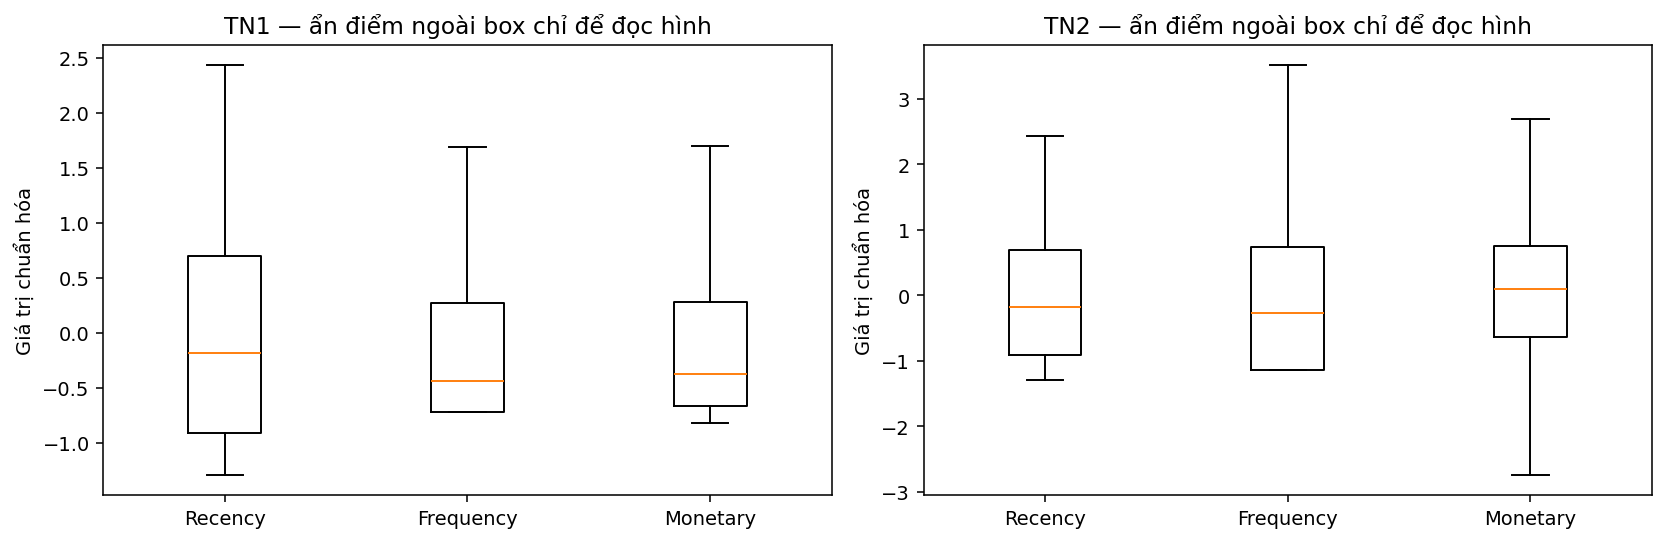

Ví dụ khoảng cách Euclid giữa khách M lớn nhất và khách gần trung vị M: TN1=17.701, TN2=4.148. Đây là minh họa biến đổi khoảng cách, không chứng minh cặp nào quan trọng hơn.

In [10]:
z1,s1=feature_matrix(f,'TN1');z2,s2=feature_matrix(f,'TN2')
stats=[]
for name,z in [('TN1',z1),('TN2',z2)]:
 for j,col in enumerate(FEATURES):stats.append({'Thí nghiệm':name,'Đặc trưng':col,'Mean':z[:,j].mean(),'Std':z[:,j].std(),'P99':np.quantile(z[:,j],.99),'Max':z[:,j].max()})
study.table('scaled_summary','Thang đo sau biến đổi',pd.DataFrame(stats))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')
study.fig('transformed_boxplots','Thang đo hai thí nghiệm',fig)
hi=f.Monetary.astype(float).idxmax();med=(f.Monetary.astype(float)-f.Monetary.astype(float).median()).abs().idxmin()
study.note(f'Ví dụ khoảng cách Euclid giữa khách M lớn nhất và khách gần trung vị M: TN1={np.linalg.norm(z1[hi]-z1[med]):.3f}, TN2={np.linalg.norm(z2[hi]-z2[med]):.3f}. Đây là minh họa biến đổi khoảng cách, không chứng minh cặp nào quan trọng hơn.')

## PC02.8 — Đặc trưng hành vi và quyết định sử dụng

**Câu hỏi:** thông tin ngoài RFM có thể bổ sung gì mà không tạo kết luận vượt nguồn?

Với khách c, tổng đơn mọi trạng thái trong cùng khoảng là $N_c$. Tỷ trọng cancelled:

$$CancelShare_c=\frac{N_{c,cancelled}}{N_c}.$$

Tương tự returned dùng nhãn Orders; tỷ trọng có returns dùng membership bảng Returns. Hai chỉ tiêu không thay thế nhau khi một số đơn returned thiếu chi tiết. Các tỷ trọng mô tả snapshot, không xác suất một đơn mới sẽ hủy/trả.

| Biến | Câu hỏi bổ sung | Hạn chế |
|---|---|---|
| AOV=M/F | Quy mô giá trị mỗi đơn delivered | Phụ thuộc trực tiếp F/M |
| Số sản phẩm khác nhau | Độ rộng giỏ hàng quan sát | Tăng theo cơ hội mua và cách quản lý mã |
| Tỷ trọng hủy/trả | Cơ cấu kết quả đặt hàng | Không lịch sử chuyển trạng thái/nguyên nhân |
| Khoảng cách mua | Nhịp đặt đơn quan sát | Thiếu có chủ đích với khách một đơn |
| Recency mọi đơn | Có hoạt động đặt gần đây không | Không đồng nghĩa có mua delivered gần đây |

**Quyết định:** dùng RFM làm đặc trưng chính, hành vi làm profile. Mở rộng mô hình phải chỉ ra biến giải quyết câu hỏi mới, kiểm mức trùng thông tin, cách xử lý thiếu, thang đo và trọng số. Không đưa customer_id hoặc nhãn nhân khẩu học vào chỉ để tăng số chiều.

**Bàn giao PC03:** cùng tập khách và cùng RFM, hai phương án TN1/TN2, giữ ngoại lệ hợp lệ, đánh giá cả cấu trúc lẫn khả năng diễn giải.


In [11]:
b=study.behavior[study.behavior.customer_id.isin(f.customer_id)].copy()
cols=['total_orders','cancelled_share','returned_share','return_detail_share','average_order_value','distinct_products','delivered_missing_shipment_share']
study.table('behavior_summary','Đặc trưng hành vi trên tập RFM',b[cols].describe(percentiles=[.5,.9,.99]).T.reset_index(names='Đặc trưng'))
choices=pd.DataFrame([{'Đặc trưng':'R,F,M','Vai trò':'Phân cụm chính','Lý do':'Ba trục giá trị và hoạt động rõ ràng'}, {'Đặc trưng':'AOV, số SP','Vai trò':'Mô tả cụm trước','Lý do':'Phụ thuộc M/F và số lần mua'}, {'Đặc trưng':'Hủy/trả','Vai trò':'Mô tả, kiểm độ nhạy','Lý do':'Snapshot, chưa xác minh chuyển trạng thái'}, {'Đặc trưng':'signup/tenure','Vai trò':'Chưa dùng','Lý do':'Ý nghĩa signup còn giới hạn'}, {'Đặc trưng':'mean_gap','Vai trò':'Mô tả có điều kiện','Lý do':'Không có ở khách một đơn'}])
study.table('feature_decisions','Quyết định đặc trưng cho PC03',choices)
study.note('Bàn giao: TN1/TN2 trên cùng khách, không cap/xóa; các đặc trưng bổ trợ chưa là biến đầu vào. Nếu mở rộng phải chạy một thí nghiệm riêng trên cùng tập khách và kiểm trùng thông tin.')

,Đặc trưng,count,mean,std,min,50%,90%,99%,max
0,total_orders,85115.0,7.532456,8.753473,1.00,4.00,19.000000,42.0000,107.00
1,cancelled_share,85115.0,0.070507,0.119116,0.00,0.00,0.250000,0.5000,0.80
2,returned_share,85115.0,0.042562,0.093204,0.00,0.00,0.142857,0.5000,0.75
3,return_detail_share,85115.0,0.042478,0.093092,0.00,0.00,0.142857,0.5000,0.75
4,average_order_value,85115.0,24062.749594,15090.592554,445.65,22071.86,40968.788000,79123.4276,202022.56
5,distinct_products,85115.0,6.411067,7.273301,1.00,4.00,16.000000,35.0000,91.00
6,delivered_missing_shipment_share,85115.0,0.001006,0.020640,0.00,0.00,0.000000,0.0000,1.00


,Đặc trưng,Vai trò,Lý do
0,"R,F,M",Phân cụm chính,Ba trục giá trị và hoạt động rõ ràng
1,"AOV, số SP",Mô tả cụm trước,Phụ thuộc M/F và số lần mua
2,Hủy/trả,"Mô tả, kiểm độ nhạy","Snapshot, chưa xác minh chuyển trạng thái"
3,signup/tenure,Chưa dùng,Ý nghĩa signup còn giới hạn
4,mean_gap,Mô tả có điều kiện,Không có ở khách một đơn


Bàn giao: TN1/TN2 trên cùng khách, không cap/xóa; các đặc trưng bổ trợ chưa là biến đầu vào. Nếu mở rộng phải chạy một thí nghiệm riêng trên cùng tập khách và kiểm trùng thông tin.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [12]:
study.note("### Kết luận nghiệp vụ PC02 và giả thuyết cần kiểm tra")
t=concentration(study.f);one=study.f.Frequency.eq(1)
study.note(f'Khách một đơn chiếm {one.mean():.2%}. Top10% theo M đóng góp {t.loc[t.top_customer_fraction.eq(.1),"monetary_share"].iloc[0]:.2%} Net. Điều đó cho thấy cần đọc đồng thời quy mô khách và tập trung giá trị, không chỉ trung bình. Dùng TN1 làm đối chứng thang gốc chuẩn hóa và TN2 kiểm ảnh hưởng nén F/M; chưa có căn cứ xóa khách đuôi. Các biến hủy/trả/giỏ hàng bổ trợ diễn giải chứ chưa được đưa vào khoảng cách.')

### Kết luận nghiệp vụ PC02 và giả thuyết cần kiểm tra

Khách một đơn chiếm 26.84%. Top10% theo M đóng góp 39.10% Net. Điều đó cho thấy cần đọc đồng thời quy mô khách và tập trung giá trị, không chỉ trung bình. Dùng TN1 làm đối chứng thang gốc chuẩn hóa và TN2 kiểm ảnh hưởng nén F/M; chưa có căn cứ xóa khách đuôi. Các biến hủy/trả/giỏ hàng bổ trợ diễn giải chứ chưa được đưa vào khoảng cách.

## Kiểm chứng và lưu sản phẩm phân tích

Đối chiếu hash nguồn, lưu bảng/hình và manifest. Công thức, ví dụ, kết quả và diễn giải đều nằm trong notebook; báo cáo HTML được xuất từ chính nội dung này.

In [13]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC02', 'state': 'completed', 'baseline': 'v1', 'model_run': 'v1', 'tables': 13, 'figures': 6, 'commentary_blocks': 11, 'raw_unchanged': True, 'baseline_manifest_sha256': '95948f0feb349f3091a85baa3a31a557ae652fa403e35d1be425a915294c3fef'}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
